# Retail Sales Analysis (2023-2024)

**Business question:** Where does the revenue come from, where are we actually profitable, and what patterns should guide decisions?

**Dataset:** 1,218 raw order rows (practice dataset simulating a retail company) across 4 regions, 12 cities and 4 product categories.

**Workflow:** Load & inspect → Clean → Explore (EDA) → Visualize → Findings

## 1. Load & inspect the raw data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chart style: one accent colour, quiet grid
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#b9b8b2'
sns.set_style('whitegrid')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'grid.color': '#e7e6e1', 'figure.dpi': 110})

df = pd.read_csv('../data/retail_sales_data.csv')
print('Shape:', df.shape)
df.head()

Shape: (1218, 13)


,order_id,order_date,customer_name,customer_segment,region,city,category,product_name,quantity,unit_price,discount,sales,profit
0,ORD1306,2024-03-04,Rohan Gupta,Home Office,South,Hyderabad,Electronics,USB Cable,1,214.85,0.00,214.85,59.93
1,ORD1622,2023-08-24,Anjali Rao,Corporate,West,Mumbai,Furniture,Study Table,1,5740.56,0.00,5740.56,1188.11
2,ORD1704,2023-06-25,Pooja Rao,Consumer,East,Kolkata,Electronics,Bluetooth Speaker,1,1496.08,0.15,1496.08,402.17
3,ORD1458,2024-07-04,Siddharth Das,Home Office,West,Pune,Stationery,Notebook Pack,1,211.76,0.00,211.76,58.97
4,ORD1171,2023-04-13,Anjali Mehta,Home Office,South,Hyderabad,Electronics,Wireless Mouse,3,601.23,0.05,1803.69,NaN


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          1218 non-null   str    
 1   order_date        1218 non-null   str    
 2   customer_name     1218 non-null   str    
 3   customer_segment  1193 non-null   str    
 4   region            1218 non-null   str    
 5   city              1203 non-null   str    
 6   category          1218 non-null   str    
 7   product_name      1218 non-null   str    
 8   quantity          1218 non-null   int64  
 9   unit_price        1218 non-null   float64
 10  discount          1218 non-null   float64
 11  sales             1218 non-null   float64
 12  profit            1176 non-null   float64
dtypes: float64(4), int64(1), str(8)
memory usage: 123.8 KB


In [3]:
print('Missing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
print('Negative quantities:', (df['quantity'] < 0).sum())
print('\nRegion values  :', sorted(df['region'].unique()))
print('Category values:', sorted(df['category'].unique()))

Missing values:
customer_segment    25
city                15
profit              42
dtype: int64

Duplicate rows: 17
Negative quantities: 6

Region values  : [' East ', ' North ', ' South ', ' West ', 'East', 'North', 'South', 'West', 'east', 'north', 'south', 'west']
Category values: ['CLOTHING', 'Clothing', 'ELECTRONICS', 'Electronics', 'FURNITURE', 'Furniture', 'STATIONERY', 'Stationery']


**Problems found in the raw data**
- Missing values in `profit`, `customer_segment` and `city`
- Inconsistent text in `region` / `category` (casing and stray spaces)
- Exact duplicate rows
- Negative `quantity` values (data-entry errors)

## 2. Clean the data

In [4]:
raw_rows = len(df)

# 1. Standardise text
df['region'] = df['region'].str.strip().str.title()
df['category'] = df['category'].str.strip().str.title()

# 2. Missing values
df['customer_segment'] = df['customer_segment'].fillna('Unknown')   # categorical: keep the row, label it
df['city'] = df['city'].fillna('Unknown')
df['profit'] = df['profit'].fillna(df['profit'].median())            # numeric: median resists outliers

# 3. Invalid quantities: sign flipped by data entry, so take the absolute value
df['quantity'] = df['quantity'].abs()

# 4. Duplicates
df = df.drop_duplicates()

# 5. Types + recompute sales so it matches the corrected quantity
df['order_date'] = pd.to_datetime(df['order_date'])
df['sales'] = (df['quantity'] * df['unit_price']).round(2)

print(f'Rows: {raw_rows} -> {len(df)}  ({raw_rows - len(df)} duplicates removed)')
print('Missing values left:', int(df.isnull().sum().sum()))
print('Regions   :', sorted(df['region'].unique()))
print('Categories:', sorted(df['category'].unique()))
df.to_csv('../data/retail_sales_cleaned.csv', index=False)

Rows: 1218 -> 1200  (18 duplicates removed)
Missing values left: 0
Regions   : ['East', 'North', 'South', 'West']
Categories: ['Clothing', 'Electronics', 'Furniture', 'Stationery']


**Cleaning decisions (and why)**
- `profit` filled with the **median**, not the mean, so a few extreme orders don't distort the fill value.
- Missing categories become **'Unknown'** rather than dropping rows, so those orders still count in sales and profit totals.
- `sales` is **recalculated** after fixing quantities, so it stays consistent with `quantity × unit_price`.

## 3. Exploratory analysis

In [5]:
df['order_month'] = df['order_date'].dt.to_period('M').astype(str)
df['festive'] = df['order_date'].dt.month.isin([10, 11, 12])

print('Total sales :', f"{df['sales'].sum():,.0f}")
print('Total profit:', f"{df['profit'].sum():,.0f}")
print('Overall margin: {:.1f}%'.format(df['profit'].sum() / df['sales'].sum() * 100))

Total sales : 4,017,862
Total profit: 764,062
Overall margin: 19.0%


### Q1. Which category earns the most revenue, and which is most profitable per rupee?

In [6]:
cat = df.groupby('category').agg(sales=('sales', 'sum'), profit=('profit', 'sum'))
cat['margin_pct'] = (cat['profit'] / cat['sales'] * 100).round(2)
cat.sort_values('sales', ascending=False)

,sales,profit,margin_pct
category,,,
Furniture,2123189.67,392170.150,18.47
Electronics,1108402.50,219616.035,19.81
Clothing,579134.14,112324.165,19.40
Stationery,207135.23,39951.470,19.29


### Q2. Which region performs best?

In [7]:
reg = df.groupby('region').agg(sales=('sales', 'sum'), profit=('profit', 'sum'))
reg['margin_pct'] = (reg['profit'] / reg['sales'] * 100).round(2)
reg.sort_values('sales', ascending=False)

,sales,profit,margin_pct
region,,,
East,1076943.42,207421.170,19.26
North,1003852.50,182004.415,18.13
South,990449.48,189482.260,19.13
West,946616.14,185153.975,19.56


### Q3. Is there a festive-season (Oct-Dec) effect?

In [8]:
fest = df.groupby('festive').agg(orders=('order_id', 'count'),
                                 avg_order_value=('sales', 'mean'),
                                 total_sales=('sales', 'sum')).round(0)
fest.index = ['Jan-Sep', 'Oct-Dec']
fest

,orders,avg_order_value,total_sales
Jan-Sep,865,2977.0,2575170.0
Oct-Dec,335,4307.0,1442692.0


### Q4. Do discounts hurt profit margin?

In [9]:
disc = df.groupby('discount').agg(sales=('sales', 'sum'), profit=('profit', 'sum'))
disc['margin_pct'] = (disc['profit'] / disc['sales'] * 100).round(2)
disc

,sales,profit,margin_pct
discount,,,
0.00,2039880.11,434321.47,21.29
0.05,750435.89,143335.40,19.10
0.10,711804.50,119230.55,16.75
0.15,272359.71,33306.96,12.23
0.20,243381.33,33867.44,13.92


### Q5. Top products, customer segments and cities

In [10]:
print('Top 5 products by units sold')
print(df.groupby('product_name')['quantity'].sum().sort_values(ascending=False).head(5))
print('\nProfit by customer segment')
print(df.groupby('customer_segment')['profit'].sum().sort_values(ascending=False).round(0))
print('\nTop 5 cities by sales')
print(df.groupby('city')['sales'].sum().sort_values(ascending=False).head(5).round(0))

Top 5 products by units sold
product_name
Power Bank           199
Bluetooth Speaker    190
USB Cable            175
Stapler              170
Sticky Notes         161
Name: quantity, dtype: int64

Profit by customer segment
customer_segment
Home Office    267499.0
Corporate      265427.0
Consumer       224830.0
Unknown          6305.0
Name: profit, dtype: float64

Top 5 cities by sales
city
Kolkata        412437.0
Bhubaneswar    392475.0
Delhi          386559.0
Chennai        356374.0
Chandigarh     341737.0
Name: sales, dtype: float64


## 4. Visualizations

### Chart 1: Revenue by category

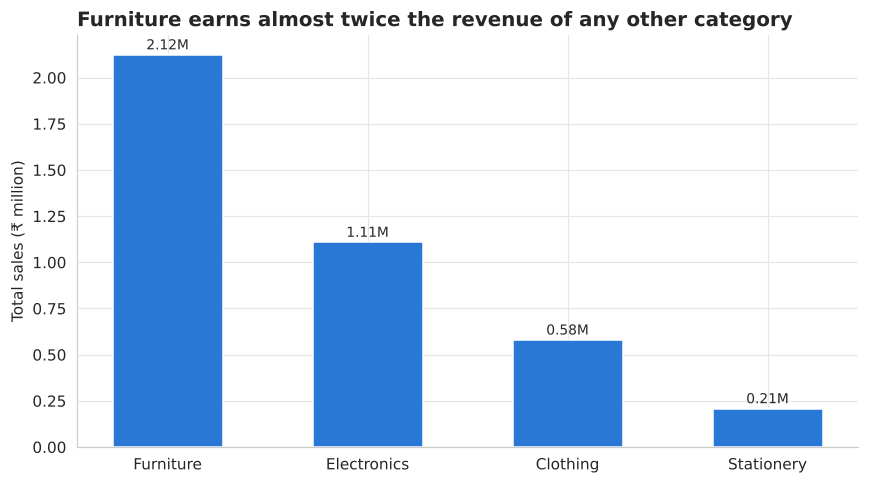

In [11]:
s = cat['sales'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(s.index, s.values / 1e6, color=BLUE, width=0.55)
ax.set_title('Furniture earns almost twice the revenue of any other category', loc='left')
ax.set_ylabel('Total sales (₹ million)')
ax.set_xlabel('')
for b, v in zip(bars, s.values):
    ax.text(b.get_x() + b.get_width() / 2, v / 1e6 + 0.03, f'{v/1e6:.2f}M', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('../images/01_revenue_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

### Chart 2: Profit margin by category (the surprise)

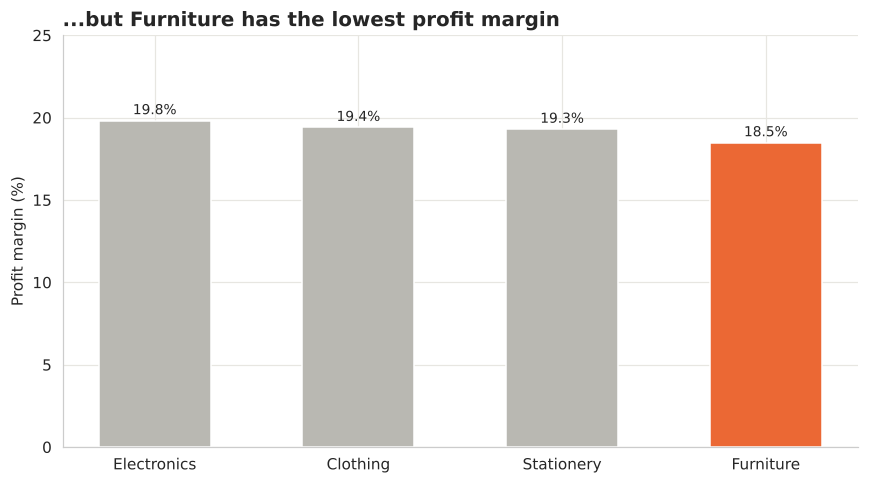

In [12]:
m = cat['margin_pct'].sort_values(ascending=False)
colors = [ORANGE if c == 'Furniture' else GREY for c in m.index]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(m.index, m.values, color=colors, width=0.55)
ax.set_ylim(0, 25)
ax.set_title('...but Furniture has the lowest profit margin', loc='left')
ax.set_ylabel('Profit margin (%)')
for b, v in zip(bars, m.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('../images/02_margin_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

### Chart 3: Monthly sales trend

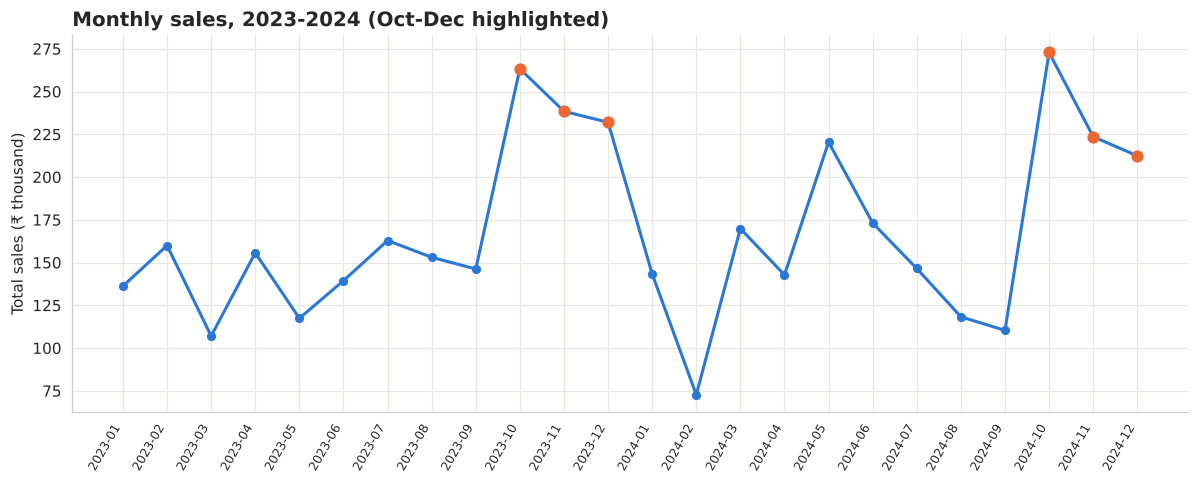

In [13]:
mon = df.groupby('order_month')['sales'].sum()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(range(len(mon)), mon.values / 1e3, color=BLUE, linewidth=2, marker='o', markersize=5)
for i, label in enumerate(mon.index):
    if label[-2:] in ('10', '11', '12'):
        ax.plot(i, mon.values[i] / 1e3, 'o', color=ORANGE, markersize=7)
ax.set_xticks(range(len(mon)))
ax.set_xticklabels(mon.index, rotation=60, ha='right', fontsize=8)
ax.set_ylabel('Total sales (₹ thousand)')
ax.set_title('Monthly sales, 2023-2024 (Oct-Dec highlighted)', loc='left')
plt.tight_layout()
plt.savefig('../images/03_monthly_sales_trend.png', dpi=150, bbox_inches='tight')
plt.show()

### Chart 4: Festive vs rest of year (average order value)

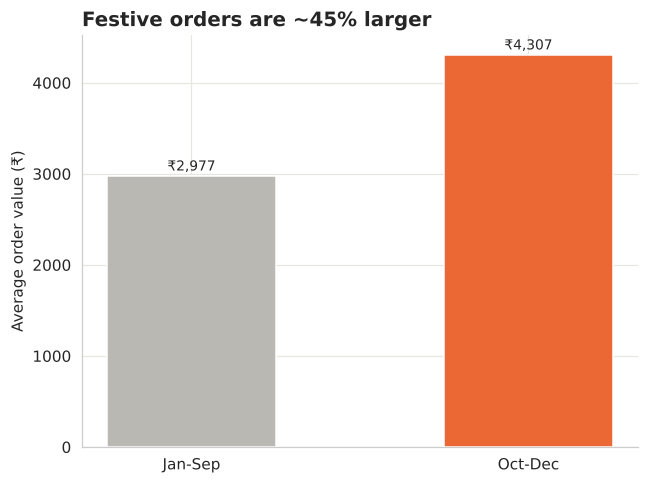

In [14]:
aov = df.groupby('festive')['sales'].mean()
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(['Jan-Sep', 'Oct-Dec'], aov.values, color=[GREY, ORANGE], width=0.5)
ax.set_ylabel('Average order value (₹)')
ax.set_title('Festive orders are ~45% larger', loc='left')
for b, v in zip(bars, aov.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f'₹{v:,.0f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('../images/04_festive_vs_regular.png', dpi=150, bbox_inches='tight')
plt.show()

### Chart 5: Discount level vs profit margin

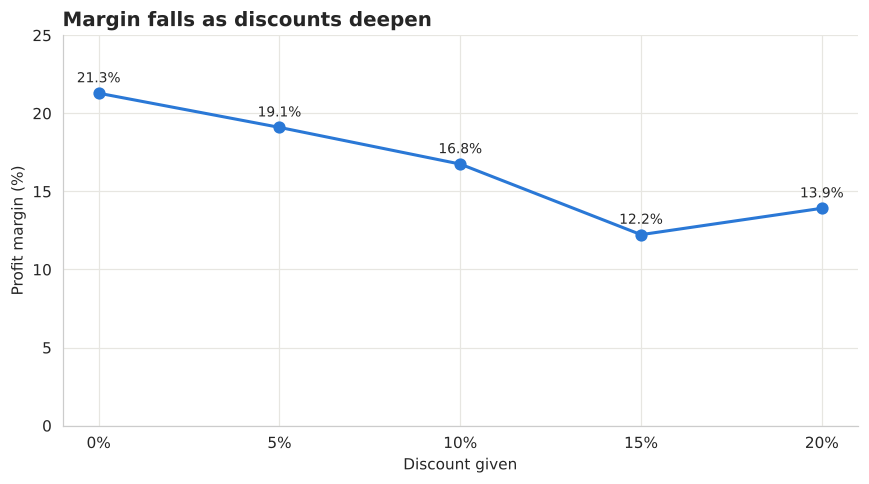

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(disc.index * 100, disc['margin_pct'], color=BLUE, linewidth=2, marker='o', markersize=7)
for x, y in zip(disc.index * 100, disc['margin_pct']):
    ax.text(x, y + 0.7, f'{y:.1f}%', ha='center', fontsize=9)
ax.set_xticks(disc.index * 100)
ax.set_xticklabels([f'{int(d*100)}%' for d in disc.index])
ax.set_ylim(0, 25)
ax.set_xlabel('Discount given')
ax.set_ylabel('Profit margin (%)')
ax.set_title('Margin falls as discounts deepen', loc='left')
plt.tight_layout()
plt.savefig('../images/05_discount_vs_margin.png', dpi=150, bbox_inches='tight')
plt.show()

### Chart 6: Sales by region and category

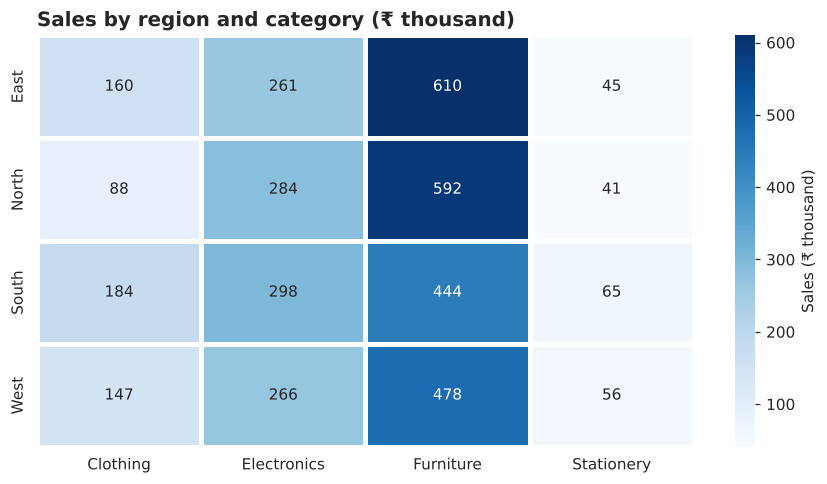

In [16]:
pivot = df.pivot_table(values='sales', index='region', columns='category', aggfunc='sum') / 1e3
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Blues', linewidths=2, linecolor='white',
            cbar_kws={'label': 'Sales (₹ thousand)'}, ax=ax)
ax.set_title('Sales by region and category (₹ thousand)', loc='left')
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout()
plt.savefig('../images/06_region_category_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Key findings

In [17]:
top_cat = cat['sales'].idxmax()
low_margin = cat['margin_pct'].idxmin()
print(f"1. {top_cat} is the top category by revenue ({cat['sales'].max():,.0f}), "
      f"almost double the next one.")
print(f"2. {low_margin} has the LOWEST margin ({cat['margin_pct'].min():.1f}%), "
      f"so highest revenue does not mean highest efficiency.")
print(f"3. Regions are close; {reg['sales'].idxmax()} leads with {reg['sales'].max():,.0f} "
      f"(spread across regions is only ~{(reg['sales'].max()/reg['sales'].min()-1)*100:.0f}%).")
print(f"4. Festive (Oct-Dec) average order value is ₹{aov[True]:,.0f} vs ₹{aov[False]:,.0f} "
      f"({(aov[True]/aov[False]-1)*100:.0f}% higher).")
print(f"5. Margin drops from {disc['margin_pct'].iloc[0]:.1f}% (no discount) to "
      f"{disc['margin_pct'].min():.1f}% at the worst discount tier.")

1. Furniture is the top category by revenue (2,123,190), almost double the next one.
2. Furniture has the LOWEST margin (18.5%), so highest revenue does not mean highest efficiency.
3. Regions are close; East leads with 1,076,943 (spread across regions is only ~14%).
4. Festive (Oct-Dec) average order value is ₹4,307 vs ₹2,977 (45% higher).
5. Margin drops from 21.3% (no discount) to 12.2% at the worst discount tier.


## 6. Recommendations
1. **Review Furniture pricing and costs.** It is the biggest revenue driver but the least efficient; even a 1-point margin gain is worth more than the same gain in any smaller category.
2. **Cap discounts at 10%.** Margin falls steeply beyond that, with little evidence the extra discount creates enough volume to compensate.
3. **Plan stock and promotions for Oct-Dec.** Orders are larger in the festive quarter.

*Limitations:* this is a simulated practice dataset, and the analysis does not test for statistical significance.